# Ungraded Lab:  Logistic Regression using Scikit-Learn




## Goals
In this lab you will:
-  Train a logistic regression model using scikit-learn.

-  中文官方文档: https://scikit-learn.org.cn

## Dataset 
Let's start with the same dataset as before.

In [1]:
import numpy as np

X = np.array([[0.5, 1.5], [1,1], [1.5, 0.5], [3, 0.5], [2, 2], [1, 2.5]])
y = np.array([0, 0, 0, 1, 1, 1])

## Fit the model

The code below imports the [logistic regression model](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression) from scikit-learn. You can fit this model on the training data by calling `fit` function.

In [2]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression()
lr_model.fit(X, y)

LogisticRegression()

## Make Predictions

You can see the predictions made by this model by calling the `predict` function.

In [3]:
y_pred = lr_model.predict(X)

print("Prediction on training set:", y_pred)

Prediction on training set: [0 0 0 1 1 1]


## Calculate accuracy

You can calculate this accuracy of this model by calling the `score` function.

In [4]:
print("Accuracy on training set:", lr_model.score(X, y))

Accuracy on training set: 1.0


## 使用scikit-learn生成数据并预测(可选)

In [8]:
import numpy as np  
import matplotlib.pyplot as plt  
from sklearn.datasets import make_classification  
from sklearn.linear_model import LogisticRegression  
from sklearn.model_selection import train_test_split  
from sklearn.metrics import accuracy_score

# 课程勘误：后面的评估单元格还会调用两个未导入的函数。
# 若出现 NameError，请取消下面两行的注释，再重新运行本格及后面的评估单元格。
# from sklearn.metrics import confusion_matrix
# from sklearn.metrics import classification_report


In [18]:
# 生成二分类数据  
X, y = make_classification(n_samples=1000,n_classes=2, n_features=2, n_clusters_per_class=1, random_state=42, n_redundant = 0 )  

In [19]:
# 检查数据形状  
print(f"X shape: {X.shape}")  
print(f"y shape: {y.shape}")

X shape: (1000, 2)
y shape: (1000,)


In [21]:
# 划分数据集  
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [22]:
# 训练逻辑回归模型  
model = LogisticRegression()  
model.fit(X_train, y_train)

LogisticRegression()

In [24]:
# 进行预测  
y_pred = model.predict(X_test)  
  
# 评估模型性能(li) 
accuracy = accuracy_score(y_test, y_pred)  
conf_matrix = confusion_matrix(y_test, y_pred)  
class_report = classification_report(y_test, y_pred)  
  
print(f"Accuracy: {accuracy}")  
print("Confusion Matrix:")  
print(conf_matrix)  
print("Classification Report:")  
print(class_report) 

Accuracy: 0.8833333333333333
Confusion Matrix:
[[137  10]
 [ 25 128]]
Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.93      0.89       147
           1       0.93      0.84      0.88       153

    accuracy                           0.88       300
   macro avg       0.89      0.88      0.88       300
weighted avg       0.89      0.88      0.88       300



In [25]:
# 可视化数据和决策边界（仅适用于二维数据）  
def plot_decision_boundary(X, y, model):  
    # 创建一个网格来评估模型  
    h = .02  # 网格中的步长  
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1  
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1  
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))  
      
    # 预测网格中每个点的类别  
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])  
    Z = Z.reshape(xx.shape)  
      
    # 绘制决策边界和数据点  
    plt.contourf(xx, yy, Z, alpha=0.8)  
    scatter = plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o')  
    plt.title("Decision Boundary")  
    plt.xlabel("Feature 1")  
    plt.ylabel("Feature 2")  
    plt.legend(*scatter.legend_elements(), title="Classes")  
    plt.show()  


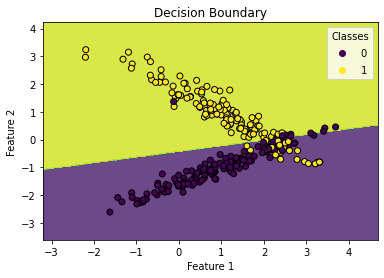

In [26]:
# 调用函数可视化决策边界  
plot_decision_boundary(X_test, y_test, model)